# M09-2 | ORT 怎麼執行 QDQ ONNX：五個圖最佳化等級與 QDQ node fusion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m09_onnx_runtime/02_ort_qdq_fusion.ipynb)

M09-1 的 QDQ ONNX 裡沒有任何 int8 kernel，只有 `QuantizeLinear`／`DequantizeLinear` 包著 fp32 的 `Conv`。把它換成 int8 kernel 的是 ONNX Runtime（ORT）：建 `InferenceSession` 時，ORT 依**圖最佳化等級**改寫圖，再把每個 node 交給一個 Execution Provider（EP）執行。

```text
QDQ ONNX（M09-1）
  → ort.InferenceSession(…, sess_options, providers)   選 EP、依最佳化等級改寫圖
  → session.run                                         執行改寫後的圖
```

- **A.** 這個 ORT build 有哪些 EP。
- **B.** 五個等級各把 TinyConvNet 的 QDQ ONNX 改成什麼。

每一級在 ORT 原始碼裡登記了哪些改寫，在 [M09 概覽](00_overview.ipynb)；各種 op 會被怎麼處理，在 M09-3。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m09_onnx_runtime")

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import onnx
import onnxruntime as ort
import torch
from onnx import numpy_helper

from common.pt2e import quiet  # 必須在 onnx／torchao 之前 import
from common.data import trained_tiny_net
from common.env import env_summary
from common.models import example_inputs
from common.onnx_utils import LEVELS, onnx_op_counts, optimized_model, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f"｜onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


輸入是 M09-1 的 QDQ ONNX：PT2E（`xnnpack_qdq`）產生 Q/DQ 圖，再 `torch.onnx.export(Q/DQ 圖, x, dynamo=True)`（`to_onnx`）匯出。

In [2]:
x = example_inputs()
onnx_model = to_onnx(xnnpack_qdq(trained_tiny_net(), x), x)

## A. 這個 ORT build 有哪些 EP

In [3]:
print("ort.get_available_providers()：", ort.get_available_providers())

ort.get_available_providers()： ['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']


本章建 session 時一律指定 `providers=["CPUExecutionProvider"]`：每個 ORT build 都有這個 EP，它的 kernel 是 ORT 自己的 MLAS，和 M08 的 XNNPACK 是兩套不同的實作。EP 是什麼、清單的順序怎麼決定用哪一個，見 M07 概覽〈同一個函式庫，可以接在好幾個框架下〉。

## B. 五個圖最佳化等級

ORT 1.30 有五個等級，每一級包含前一級（細節在 M09 概覽）：

| 等級 | 這一級新加的 |
|---|---|
| `ORT_DISABLE_ALL` | 只跑必要的步驟，例如讓每個 DQ 只給一個 op 用 |
| `ORT_ENABLE_BASIC` | 與 EP 無關的化簡；bias 量化成 int32 |
| `ORT_ENABLE_EXTENDED` | QDQ node fusion：`DQ → op → Q` 換成 int8 op |
| `ORT_ENABLE_LAYOUT` | CPU 的 layout：int8 Conv 換成 NHWC |
| `ORT_ENABLE_ALL` | fp16 常數轉 fp32；`InferenceSession` 的預設 |

怎麼看到 ORT 改寫後的圖？建 session 時給 `SessionOptions.optimized_model_filepath`，ORT 就把改寫後的圖存成 `.onnx`：

In [4]:
so = ort.SessionOptions()
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
with tempfile.TemporaryDirectory() as d:
    so.optimized_model_filepath = str(Path(d) / "optimized.onnx")
    ort.InferenceSession(onnx_model.SerializeToString(), so, providers=["CPUExecutionProvider"])
    extended = onnx.load(so.optimized_model_filepath)
print("EXTENDED 改寫後：", dict(onnx_op_counts(extended)))

EXTENDED 改寫後： {'QuantizeLinear': 2, 'QLinearConv': 4, 'MaxPool': 2, 'com.microsoft.QLinearAdd': 1, 'DequantizeLinear': 2, 'ReduceMean': 1, 'Reshape': 1, 'com.microsoft.QGemm': 1}


平常建 session 時 ORT 也做同樣的改寫，只是不存檔。本專案把這幾行包成 `optimized_model(onnx_model, level)`（`common/onnx_utils.py`）。五個等級各做一次，比較 op 的個數：

In [5]:
graphs = {"匯出的 QDQ ONNX": onnx_model} | {lv: optimized_model(onnx_model, lv) for lv in LEVELS}
counts = {name: onnx_op_counts(g) for name, g in graphs.items()}
ops = sorted(set().union(*counts.values()), key=lambda o: (-counts["匯出的 QDQ ONNX"].get(o, 0), o))
table([[op] + [counts[name].get(op, "") for name in graphs] for op in ops],
      ["op"] + [name.replace("ORT_", "") for name in graphs])

op,匯出的 QDQ ONNX,DISABLE_ALL,ENABLE_BASIC,ENABLE_EXTENDED,ENABLE_LAYOUT,ENABLE_ALL
DequantizeLinear,16,17,22,2,2,2
QuantizeLinear,11,11,11,2,2,2
Conv,4,4,4,,,
Relu,4,4,4,,,
MaxPool,2,2,2,2,,
Add,1,1,1,,,
Gemm,1,1,1,,,
ReduceMean,1,1,1,1,1,1
Reshape,1,1,1,1,1,1
QLinearConv,,,,4,,


下面一級一級看。

### `ORT_DISABLE_ALL`：DequantizeLinear 多了一個

「關掉最佳化」也改了圖。看 M09-1 A 段那個被合併的 DequantizeLinear：

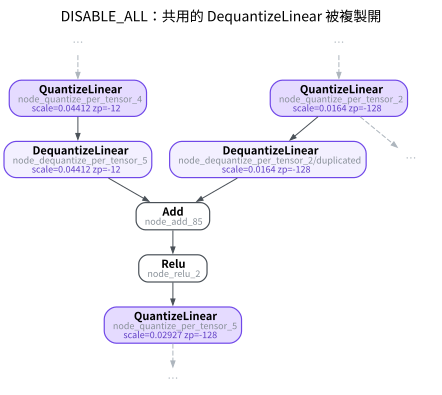

In [6]:
draw_onnx(graphs["ORT_DISABLE_ALL"], focus=lambda n: n.op_type == "Add", hops=2,
          title="DISABLE_ALL：共用的 DequantizeLinear 被複製開")

In [7]:
dup = [n.name for n in graphs["ORT_DISABLE_ALL"].graph.node if n.name.endswith("/duplicated")]
print("名稱帶 /duplicated 的 node：", dup)
assert len(dup) >= 1

名稱帶 /duplicated 的 node： ['node_dequantize_per_tensor_2/duplicated']


原本一個 DequantizeLinear 同時給 `Add` 和下一個 `Conv` 用，現在 `Add` 有自己的一份（`…/duplicated`）。這是 ORT 的 `EnsureUniqueDQForNodeUnit`：後面的 fusion 以「DQ → op → Q」為單位（node unit）改寫，每個單元要有自己的 DQ。原始碼把它列為必要的步驟，連 DISABLE_ALL 也跑。

### `ORT_ENABLE_BASIC`：bias 變成 int32

DequantizeLinear 又多了幾個。看第一個 conv：

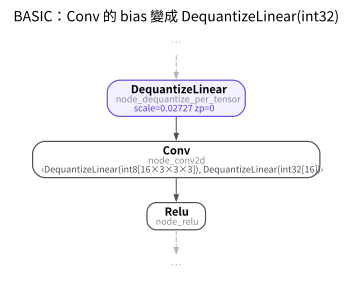

In [8]:
basic = graphs["ORT_ENABLE_BASIC"]
draw_onnx(basic, focus="node_conv2d", hops=1, title="BASIC：Conv 的 bias 變成 DequantizeLinear(int32)")

Conv 的第三個輸入原本是 float32 的 bias，現在是 `DequantizeLinear(int32[…])`：ORT 把 fp32 bias 量化成 int32（原始碼的 `WeightBiasQuantization`）。檢查 int32 bias 是不是 $\operatorname{round}(b / (s_x \cdot s_w))$，$s_x$ 是 Conv 輸入的 scale、$s_w$ 是 weight 的 per-channel scale：

In [9]:
def consts(model):
    return {i.name: numpy_helper.to_array(i) for i in model.graph.initializer}


def conv_node(model):
    return next(n for n in model.graph.node if n.name == "node_conv2d")


src, by_out = consts(onnx_model), {n.output[0]: n for n in onnx_model.graph.node}
conv = conv_node(onnx_model)
s_x = float(src[by_out[conv.input[0]].input[1]])            # 輸入 DequantizeLinear 的 scale
s_w = src[by_out[conv.input[1]].input[1]]                   # weight DequantizeLinear 的 per-channel scale
b_fp32 = src[conv.input[2]]
b_by_out = {n.output[0]: n for n in basic.graph.node}
b_int32 = consts(basic)[b_by_out[conv_node(basic).input[2]].input[0]]
same = np.array_equal(b_int32, np.round(b_fp32 / (s_x * s_w)).astype(np.int32))
print(f"int32 bias == round(fp32 bias / (s_x · s_w))：{same}")
assert b_int32.dtype == np.int32 and same

int32 bias == round(fp32 bias / (s_x · s_w))：True


和 M08 的 XNNPACK 一樣，scale 是 $s_x \cdot s_w$。差別在時間點：XNNPACK 在匯出 `.pte` 時做，ORT 在建 session 時做。

### `ORT_ENABLE_EXTENDED`：QDQ node fusion

從這一級起才有 int8 kernel。第一個 conv 單元：

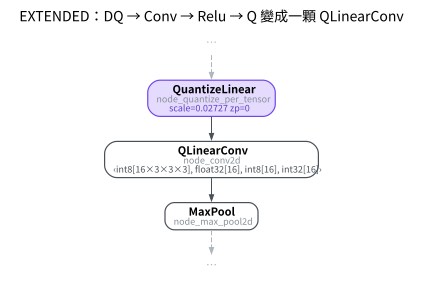

In [10]:
ext = graphs["ORT_ENABLE_EXTENDED"]
draw_onnx(ext, focus="node_conv2d", hops=1, title="EXTENDED：DQ → Conv → Relu → Q 變成一顆 QLinearConv")

原本的「DequantizeLinear → Conv → Relu → QuantizeLinear」變成一顆 `QLinearConv`：輸入輸出都是 int8，`‹…›` 裡依序是 int8 weight、weight 的 scale 與 zero point、int32 bias（BASIC 做好的）。輸入與輸出的 scale、zero point 也是它的參數（純量，沒有印出來）。

Relu 去哪了？看 Relu 後面那個 QuantizeLinear 的 zero point：

In [11]:
nodes = list(onnx_model.graph.node)
relu = next(n for n in nodes if n.op_type == "Relu")
q = next(n for n in nodes if n.op_type == "QuantizeLinear" and n.input[0] == relu.output[0])
zp = src[q.input[2]]
print(f"Relu 後面的 QuantizeLinear：zero point = {int(zp)}，{zp.dtype} 的下限 = {np.iinfo(zp.dtype).min}")
assert int(zp) == np.iinfo(zp.dtype).min

Relu 後面的 QuantizeLinear：zero point = -128，int8 的下限 = -128


zero point 就是 int8 的下限，實數 0 對應到 -128，負數在 QuantizeLinear 裡本來就會被 clamp 到 -128。Relu 在量化之後不改變任何值，ORT 就把它拿掉（原始碼的 `ReluQuantFusion`，只在 zero point 等於下限時做）。zero point 會是下限，是因為 observer 看到的 relu 輸出最小值就是 0。

不是每個單元都能換。看 `ReduceMean`（`AdaptiveAvgPool2d(1)` 匯出成的 op）附近：

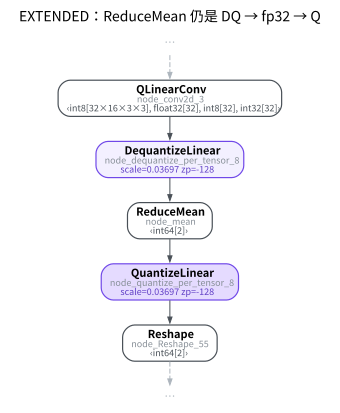

In [12]:
draw_onnx(ext, focus=lambda n: n.op_type == "ReduceMean", hops=2, title="EXTENDED：ReduceMean 仍是 DQ → fp32 → Q")

In [13]:
dq_out = {n.output[0] for n in ext.graph.node if n.op_type == "DequantizeLinear"}
fp32_ops = sorted({n.op_type for n in ext.graph.node if n.op_type != "QuantizeLinear" and set(n.input) & dq_out})
print("EXTENDED 之後仍吃 DequantizeLinear 輸出的 op：", fp32_ops)
assert fp32_ops == ["ReduceMean"]

EXTENDED 之後仍吃 DequantizeLinear 輸出的 op： ['ReduceMean']


- `ReduceMean` 不在 QDQ fusion 的清單上，仍是「DQ → fp32 運算 → Q」，前後各一次 int8 ↔ fp32 轉換。
- 它下面的 `Reshape`，和前面的 `MaxPool` 一樣，前後的 Q/DQ 被拿掉、直接在 int8 上做：只搬資料或取大小的 op，在 int8 上做結果不變。
- 圖的入口剩一個 QuantizeLinear、出口剩一個 DequantizeLinear，是真正的 fp32 ↔ int8 轉換。

哪些 op 屬於哪一組，M09-3 用一個有更多種 op 的模型看。

### `ORT_ENABLE_LAYOUT`：int8 Conv 換成 NHWC

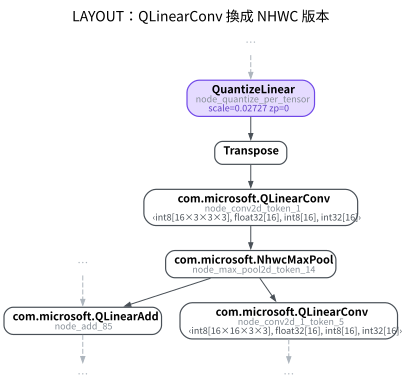

In [14]:
layout = graphs["ORT_ENABLE_LAYOUT"]
first_conv = next(n.name for n in layout.graph.node if n.op_type == "QLinearConv")  # NHWC 版本換了 node 名稱
draw_onnx(layout, focus=first_conv, hops=2, title="LAYOUT：QLinearConv 換成 NHWC 版本")

`NhwcTransformer` 把 `QLinearConv` 換成 NHWC 版本的 `com.microsoft.QLinearConv`，在 int8 區段的前後插 `Transpose`；夾在中間的 `MaxPool` 也變成 `com.microsoft.NhwcMaxPool`。`com.microsoft.*` 是 ORT 自己定義的 op，不在 ONNX 標準裡，只有 ORT 看得懂。

### `ORT_ENABLE_ALL`

In [15]:
same = [n.op_type for n in graphs["ORT_ENABLE_ALL"].graph.node] == [n.op_type for n in graphs["ORT_ENABLE_LAYOUT"].graph.node]
print("ALL 與 LAYOUT 改寫出的圖相同：", same)
assert same

ALL 與 LAYOUT 改寫出的圖相同： True


ALL 只比 LAYOUT 多「fp16 常數轉 fp32」，這個模型沒有 fp16 常數，所以兩者一樣。

## 小結

- QDQ ONNX 是後端中立的：檔案裡只有標準的 `QuantizeLinear`／`DequantizeLinear`，要不要換成 int8 kernel，由執行時的 EP 與最佳化等級決定。
- DISABLE_ALL 也會複製共用的 DQ；BASIC 把 bias 量化成 int32；EXTENDED 起 Conv 才是 int8，Relu 被併進 Q；LAYOUT 換 NHWC；ALL 只多 fp16 的處理。
- 不在 fusion 清單上的 op（這裡是 `ReduceMean`）留在 fp32。
- 同一個 `.onnx` 在 x86 上會被改得不同（M09 概覽〈與平台有關〉）。